# Two stability techniques for trillion-parameter MoE training: SwiGLU clamping and Anticipatory Routing
### Notebook 5 of 9 on DeepSeek-V4 (technical report [arXiv:2606.19348](https://arxiv.org/abs/2606.19348), §4.2.3)

Training a trillion-parameter mixture-of-experts model produced loss spikes. The report says simple rollbacks "could temporarily restore the training state" but "do not prevent the recurrence of loss spikes"; the occurrence of spikes "is consistently tied to outliers in the MoE layers, and the routing mechanism itself appears to exacerbate the emergence of these outliers". Two practical fixes, from two directions, "breaking the vicious cycle induced by routing, and directly suppressing anomalous values":

- **Anticipatory Routing.** At step `t`, features are computed with the current parameters `θ_t`, but the routing *indices* come from historical parameters `θ_{t−Δt}`. To avoid loading parameters twice, the data for step `t` is fetched at step `t−Δt` and its routing indices are computed and cached then. Overhead: "approximately 20 %" extra wall-clock when active; it is switched on only after a loss spike (a short rollback, then a period of anticipatory routing, then back to normal), so the overall overhead is "negligible".
- **SwiGLU clamping.** The linear component of SwiGLU is clamped to `[−10, 10]` and the upper bound of the gate component is capped at 10, in both Flash and Pro, throughout training, "without compromising performance".

The report is explicit about what it lacks: "a comprehensive theoretical understanding of their underlying mechanisms remains an open question". We therefore do not try to explain *why* they work. We implement both, verify that they do what they are specified to do, measure the cost side, and say plainly that we **did not reproduce a loss-spike cure**: our model is a toy that has no trillion-parameter instability to cure.

| section | question | number it carries |
|---|---|---|
| 1 | What does clamping bound? | output growth vs input scale |
| 2 | What does clamping cost? | gradient through clamped units |
| 3 | What are "historical routing indices", exactly? | routing agreement vs staleness `Δt` |
| 4 | Does anticipatory routing still train? | loss vs standard routing |
| 5 | How does the spike-triggered controller work? | fraction of steps with the overhead |
| 6 | What does the overhead mean in compute terms? | ~20 % while active |

In [1]:
import math, time, itertools
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
CHECKS = []
def check(name, ok, detail=""): CHECKS.append((name, bool(ok), detail)); print(("PASS " if ok else "FAIL ") + name + (f"   [{detail}]" if detail else ""))

## What clamping bounds

A SwiGLU expert computes `h = silu(W_g x) ⊙ (W_u x)`, a **product** of two linear projections (one passed through a smooth gate), so if the input `x` has an outlier of size `s`, the output grows like `s²`: an outlier of 100 is not amplified 100× but 10,000×. Clamping caps each factor. The report's description, "clamped the linear component ... to the range of [−10, 10], while capping the upper bound of the gate component at 10", leaves the exact placement to the code; we take the natural reading: `g ← min(W_g x, 10)`, `u ← clamp(W_u x, −10, 10)`, `h = silu(g) ⊙ u`.

Tiny example: pre-activations `g = 50`, `u = 50`. Unclamped: `silu(50)·50 ≈ 2,500`. Clamped: `silu(10)·10 ≈ 100`. The cap is on the product's range: `|h| ≤ silu(10) · 10 ≈ 100`.

In [2]:
def swiglu(g, u, clamp=True, lim=10.0):
    if clamp: g = g.clamp(max=lim); u = u.clamp(-lim, lim)             # gate upper bound 10; linear component in [-10, 10]
    return F.silu(g) * u
print("g=u=50:  unclamped", swiglu(torch.tensor(50.), torch.tensor(50.), clamp=False).item(), "  clamped", round(swiglu(torch.tensor(50.), torch.tensor(50.)).item(), 2))
check("worked example: clamped SwiGLU at g=u=50 is silu(10)*10 = 100 (4 s.f.)", abs(swiglu(torch.tensor(50.), torch.tensor(50.)).item() - F.silu(torch.tensor(10.)).item() * 10) < 1e-4)
torch.manual_seed(0); d, h = 64, 128; Wg, Wu = torch.randn(h, d) * d ** -.5, torch.randn(h, d) * d ** -.5; x0 = torch.randn(256, d)
print(f"{'input scale':>12s} {'|h| max unclamped':>20s} {'|h| max clamped':>18s} {'mean |h| unclamped':>20s} {'mean |h| clamped':>18s}")
rows = []
for sc in [1, 10, 100, 1000]:
    x = x0 * sc; a = swiglu(x @ Wg.T, x @ Wu.T, clamp=False); b = swiglu(x @ Wg.T, x @ Wu.T); rows.append((sc, a.abs().max().item(), b.abs().max().item(), a.abs().mean().item(), b.abs().mean().item()))
    print(f"{sc:12d} {rows[-1][1]:20.3e} {rows[-1][2]:18.2e} {rows[-1][3]:20.3e} {rows[-1][4]:18.2e}")
check("unclamped output grows ~quadratically with the input scale (x100 input -> >5000x output)", rows[2][3] / rows[0][3] > 5000, f"{rows[2][3] / rows[0][3]:.0f}x")
check("clamped output never exceeds silu(10)*10 ~ 100, whatever the input scale", all(r[2] <= F.silu(torch.tensor(10.)).item() * 10 + 1e-3 for r in rows), f"max {max(r[2] for r in rows):.1f}")

g=u=50:  unclamped 2500.0   clamped 100.0
PASS worked example: clamped SwiGLU at g=u=50 is silu(10)*10 = 100 (4 s.f.)
 input scale    |h| max unclamped    |h| max clamped   mean |h| unclamped   mean |h| clamped
           1            1.080e+01           1.08e+01            3.207e-01           3.21e-01
          10            1.109e+03           1.00e+02            3.201e+01           1.99e+01
         100            1.109e+05           1.00e+02            3.201e+03           4.63e+01
        1000            1.109e+07           1.00e+02            3.201e+05           4.98e+01
PASS unclamped output grows ~quadratically with the input scale (x100 input -> >5000x output)   [9982x]
PASS clamped output never exceeds silu(10)*10 ~ 100, whatever the input scale   [max 100.0]


## What clamping costs

A clamp has zero gradient outside its range. A unit whose gate or linear pre-activation is pinned at the clamp passes **no gradient** to its input weights through that path, so such a unit cannot be pulled back by the loss; this is the price of the bound. We measure the gradient of the output norm with respect to the input as the input scale grows.

In [3]:
def grad_norm(sc, clamp):
    x = (x0 * sc).clone().requires_grad_(True); swiglu(x @ Wg.T, x @ Wu.T, clamp=clamp).pow(2).sum().backward(); return x.grad.norm().item()
print(f"{'input scale':>12s} {'||dL/dx|| unclamped':>22s} {'||dL/dx|| clamped':>20s}   (L = sum of squared outputs)")
gr = {sc: (grad_norm(sc, False), grad_norm(sc, True)) for sc in [1, 10, 100, 1000]}
for sc, (a, b) in gr.items(): print(f"{sc:12d} {a:22.3e} {b:20.3e}")
check("unclamped gradients explode with outlier scale (x1000 input -> >1e6x gradient)", gr[1000][0] / gr[1][0] > 1e6, f"{gr[1000][0] / gr[1][0]:.1e}x")
check("clamped gradients stay bounded and shrink once most units saturate (scale 1000 gradient below scale 10's)", gr[1000][1] < gr[10][1], f"{gr[1000][1]:.1e} vs {gr[10][1]:.1e}")

 input scale    ||dL/dx|| unclamped    ||dL/dx|| clamped   (L = sum of squared outputs)
           1              7.234e+02            7.234e+02
          10              8.856e+05            1.203e+05
         100              8.855e+08            5.776e+04
        1000              8.856e+11            1.940e+04
PASS unclamped gradients explode with outlier scale (x1000 input -> >1e6x gradient)   [1.2e+09x]
PASS clamped gradients stay bounded and shrink once most units saturate (scale 1000 gradient below scale 10's)   [1.9e+04 vs 1.2e+05]


**What we found.** Clamping turns a quadratic blow-up into a hard bound, and it also bounds the gradient: at input scale 1000 the unclamped path produces a gradient about `10^9` times the scale-1 gradient, while the clamped path's gradient has *fallen* because most units are saturated. That second effect is the cost: a unit stuck beyond the clamp is not learning. The report says clamping works "without compromising performance" and does not quantify how often units saturate in the real model; we cannot either.

The other technique intervenes on the router.

## What "historical routing indices" means

Consider a standard training step: forward with `θ_t`, where the router at each MoE layer picks experts from the current hidden states and centroids. Anticipatory Routing changes **one thing**: the expert *indices* come from a forward pass with the older parameters `θ_{t−Δt}`; everything else (feature computation, the gate weights, the loss and the gradient) uses `θ_t`. In practice it is implemented as a **prefetch queue**: at step `s`, batch `s+Δt` is fetched early and its routing indices are computed with the parameters that exist at step `s`; they are cached and consumed at step `s+Δt`.

Tiny example, `Δt = 2`: at step 5, the router is run on batch 7 with `θ_5` and the indices stored; at step 7 the layer uses those stored indices with `θ_7`'s features. If `θ_7 = θ_5` this is identical to standard routing; the more the parameters move in between, the more the stored indices differ from what `θ_7` would have chosen.

We build a small MoE language model so that "parameters move" is real: 2 MoE layers, 8 experts per layer with top-2, shared expert, width 48, character-level on Python source text (the installed `torch` package), with the V4 affinity `Sqrt(Softplus)`. The router can take **forced indices**, which is all anticipatory routing needs.

In [4]:
import os, glob, copy
import torch as _t
_files = sorted(glob.glob(os.path.dirname(_t.__file__) + "/nn/modules/*.py"))[:30]
text = "".join(open(f, errors="ignore").read() for f in _files); chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; data = torch.tensor([stoi[c] for c in text])
V, T = len(chars), 64
sqsp = lambda x: F.softplus(x).sqrt()
def rms(x): return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + 1e-6)
class Expert(nn.Module):
    def __init__(s, d, h): super().__init__(); s.g = nn.Linear(d, h, bias=False); s.u = nn.Linear(d, h, bias=False); s.dn = nn.Linear(h, d, bias=False)
    def forward(s, x): return s.dn(swiglu(s.g(x), s.u(x)))
class MoEBlock(nn.Module):
    def __init__(s, d, E=8, k=2, h=64, heads=4):
        super().__init__(); s.E, s.k, s.heads = E, k, heads; s.qkv = nn.Linear(d, 3 * d, bias=False); s.o = nn.Linear(d, d, bias=False)
        s.cent = nn.Parameter(torch.randn(E, d) * 0.3); s.experts = nn.ModuleList([Expert(d, h) for _ in range(E)]); s.shared = Expert(d, h)
    def forward(s, x, forced=None):                                                          # x (B,T,d); forced: (B*T,k) expert indices or None
        B, T_, d = x.shape; q, kk, v = s.qkv(rms(x)).view(B, T_, 3, s.heads, d // s.heads).permute(2, 0, 3, 1, 4)
        x = x + s.o(F.scaled_dot_product_attention(q, kk, v, is_causal=True).transpose(1, 2).reshape(B, T_, d))
        u = rms(x).reshape(-1, d); aff = sqsp(u @ s.cent.T)                                  # affinities from the CURRENT parameters
        idx = forced if forced is not None else aff.topk(s.k, dim=-1).indices                # indices: forced (anticipated) or chosen now
        gate = aff.gather(1, idx); gate = gate / gate.sum(-1, keepdim=True)                  # gates always from the current affinities (our assumption)
        out = s.shared(u)
        for e in range(s.E):
            rows, slot = (idx == e).nonzero(as_tuple=True)
            if len(rows): out = out.index_add(0, rows, gate[rows, slot, None] * s.experts[e](u[rows]))
        return x + out.view(B, T_, d), idx
class MoELM(nn.Module):
    def __init__(s, d=48, layers=2): super().__init__(); s.emb = nn.Embedding(V, d); s.pos = nn.Embedding(T, d); s.blocks = nn.ModuleList([MoEBlock(d) for _ in range(layers)]); s.head = nn.Linear(d, V, bias=False)
    def forward(s, x, forced=None):
        h = s.emb(x) + s.pos(torch.arange(x.shape[1])); idxs = []
        for l, b in enumerate(s.blocks): h, i = b(h, None if forced is None else forced[l]); idxs.append(i)
        return s.head(rms(h)), idxs
def get_batch(step, B=16):
    g = torch.Generator().manual_seed(1000 + step); i = torch.randint(0, len(data) - T - 1, (B,), generator=g); return torch.stack([data[j:j + T] for j in i]), torch.stack([data[j + 1:j + T + 1] for j in i])

torch.manual_seed(0); m = MoELM(); x, y = get_batch(0)
lo, idx0 = m(x); lo2, idx1 = m(x, forced=idx0)
check("forced indices equal to the router's own choice reproduce standard routing exactly (the Delta t = 0 case)", torch.equal(lo, lo2))
alt = [torch.randint(0, 8, i.shape) for i in idx0]; lo3, _ = m(x, forced=alt)
check("forcing different indices changes the output (the indices really are the only thing that moved)", (lo - lo3).abs().max() > 1e-4)

PASS forced indices equal to the router's own choice reproduce standard routing exactly (the Delta t = 0 case)
PASS forcing different indices changes the output (the indices really are the only thing that moved)


In [5]:
# ---- how stale are the indices?  Train normally, and at every step also compute what theta_{t-dt} would have routed for batch t ----
def train_normal(steps, lr, seed=0, snapshot_every=1, keep=12):
    torch.manual_seed(seed); m = MoELM(); opt = torch.optim.AdamW(m.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1); snaps = {}; agree = {dt: [] for dt in (1, 2, 5, 10)}; losses = []
    for t in range(steps):
        x, y = get_batch(t)
        if t > 0 and t % 5 == 0 or t < 12:
            with torch.no_grad(): idx_now = m(x)[1]
            for dt in agree:
                if t - dt in snaps:
                    sm = snaps[t - dt]
                    with torch.no_grad(): idx_old = sm(x)[1]                                       # what the OLD parameters would route for THIS batch
                    agree[dt].append(np.mean([(a.sort(-1).values == b.sort(-1).values).all(-1).float().mean().item() for a, b in zip(idx_now, idx_old)]))
        snaps[t] = copy.deepcopy(m).eval(); snaps.pop(t - 12, None)
        loss = F.cross_entropy(m(x)[0].reshape(-1, V), y.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    return m, np.array(losses), {k: float(np.mean(v)) for k, v in agree.items() if v}
rows = {}
for lr in [1e-3, 5e-3]:
    _, ls, ag = train_normal(100, lr); rows[lr] = ag
    print(f"lr {lr:g}: fraction of tokens whose expert SET (top-2, both layers averaged) is unchanged vs theta_(t-dt):  " + "  ".join(f"dt={k}: {v:.2f}" for k, v in ag.items()))
check("staleness is real: with dt = 10 at lr 5e-3 a clear fraction of routing decisions differ from the current router's", rows[5e-3][10] < 0.95, f"agreement {rows[5e-3][10]:.2f}")
check("agreement falls as dt grows (dt=10 <= dt=1)", rows[5e-3][10] <= rows[5e-3][1] + 1e-9)
check("a larger learning rate moves the router faster: agreement at dt = 5 is lower at lr 5e-3 than at 1e-3", rows[5e-3][5] < rows[1e-3][5])

lr 0.001: fraction of tokens whose expert SET (top-2, both layers averaged) is unchanged vs theta_(t-dt):  dt=1: 0.98  dt=2: 0.97  dt=5: 0.92  dt=10: 0.85


lr 0.005: fraction of tokens whose expert SET (top-2, both layers averaged) is unchanged vs theta_(t-dt):  dt=1: 0.94  dt=2: 0.89  dt=5: 0.78  dt=10: 0.74
PASS staleness is real: with dt = 10 at lr 5e-3 a clear fraction of routing decisions differ from the current router's   [agreement 0.74]
PASS agreement falls as dt grows (dt=10 <= dt=1)
PASS a larger learning rate moves the router faster: agreement at dt = 5 is lower at lr 5e-3 than at 1e-3


**What we found.** The indices of anticipatory routing are genuinely different from what the current router would pick, and the gap grows with the staleness `Δt` and the learning rate (numbers above); this is the "decoupling of the synchronous updates of the backbone network and the routing network" the report describes. The probable intuition is that a router that cannot react instantly to the latest update cannot feed an outlier back into itself within a step; but the report offers no mechanism and our toy has no instability to test it on, so we describe it as intuition, not as a finding.

Now we implement the training step as specified and check that it still trains.

## The training step with a prefetch queue

At step `s` we fetch batch `s+Δt` and run the router with the current parameters (a forward pass without gradient) to produce that batch's indices for every MoE layer; at step `t` we pop the indices computed `Δt` steps ago and run the real forward with them forced. For the first `Δt` steps there is nothing in the queue, so we warm it up. The extra pass is a full forward (later layers' routing depends on earlier layers' outputs), which is where the overhead comes from.

In [6]:
def train(steps, lr, dt=0, seed=0, B=16, spike=None, log_idx=False):
    """dt = 0: standard routing.  dt > 0: anticipatory routing with a prefetch queue of routing indices."""
    torch.manual_seed(seed); m = MoELM(); opt = torch.optim.AdamW(m.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    queue = {}; losses = []; t0 = time.time(); n_extra = 0
    for t in range(steps):
        if dt > 0:
            for s in range(t, t + dt + 1):                                                    # make sure indices exist for batches t..t+dt (warm-up at the start)
                if s not in queue:
                    with torch.no_grad(): queue[s] = m(get_batch(s, B)[0])[1]; n_extra += 1  # routing pass with the CURRENT parameters, consumed dt steps later
        x, y = get_batch(t, B); forced = queue.pop(t) if dt > 0 else None
        cur_lr = lr * (spike[1] if spike and spike[0] <= t < spike[0] + 3 else 1.0)
        for g in opt.param_groups: g["lr"] = cur_lr * min(1.0, (t + 1) / 20)
        loss = F.cross_entropy(m(x, forced=forced)[0].reshape(-1, V), y.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    return m, np.array(losses), time.time() - t0, n_extra
res = {dt: train(150, 3e-3, dt=dt) for dt in (0, 2)}
print(f"{'routing':>22s} {'final loss (last 30)':>22s} {'wall-clock (s)':>16s} {'extra routing passes':>22s}")
for dt, (_, ls, tm, ne) in res.items(): print(f"{'standard' if dt == 0 else f'anticipatory dt={dt}':>22s} {ls[-30:].mean():22.3f} {tm:16.1f} {ne:22d}")
l0, l2 = res[0][1][-30:].mean(), res[2][1][-30:].mean()
check("anticipatory routing (dt=2) trains: final loss within 0.15 nats of standard routing in this toy", abs(l0 - l2) < 0.15, f"{l2:.3f} vs {l0:.3f}")
check("it costs an extra routing forward pass per step (~150 passes for 150 steps, plus the warm-up)", res[2][3] >= 150)
print(f"measured wall-clock overhead of our (unoptimised, serial) implementation: {100 * (res[2][2] / res[0][2] - 1):.0f}%   (the report's optimised, overlapped implementation: ~20%)")
check("our serial implementation's overhead is higher than the report's overlapped ~20% (it is a full extra forward, not hidden)", res[2][2] / res[0][2] - 1 > 0.2, f"{100 * (res[2][2] / res[0][2] - 1):.0f}%")

               routing   final loss (last 30)   wall-clock (s)   extra routing passes
              standard                  2.463              2.2                      0
     anticipatory dt=2                  2.464              3.1                    152
PASS anticipatory routing (dt=2) trains: final loss within 0.15 nats of standard routing in this toy   [2.464 vs 2.463]
PASS it costs an extra routing forward pass per step (~150 passes for 150 steps, plus the warm-up)
measured wall-clock overhead of our (unoptimised, serial) implementation: 43%   (the report's optimised, overlapped implementation: ~20%)
PASS our serial implementation's overhead is higher than the report's overlapped ~20% (it is a full extra forward, not hidden)   [43%]


**What we found.** Anticipatory routing trains to a similar loss in our toy, which is all the report claims in this respect ("without compromising model performance"); our naive serial implementation costs more than the report's ~20 %, because the extra forward pass is not overlapped with anything; the report says it "carefully orchestrated the pipeline execution and the overlapping of computation with Expert Parallelism (EP) communication" to bound it. We measured no spike cure.

## Turning it on only when needed

Because the technique costs time, V4 does not run it all the time. "We introduced an automatic detection mechanism that triggers a short rollback and activates Anticipatory Routing exclusively when a loss spike occurs; after operating in this mode for a certain period, the system reverts to standard training." The detector, the rollback distance and the duration are not given. We implement a controller with our own choices: a loss-spike detector (loss above `mean + 4σ` of the recent 20 steps, floored at +0.3), a checkpoint every 10 steps, rollback to the last checkpoint older than 10 steps, anticipatory mode for 30 steps, then revert. To get a spike to detect we inject one: three steps with the learning rate multiplied by 40.

spike injected at steps 100-102 (lr x40).  controller events (detected at step, rolled back to step): [(101, 90)]


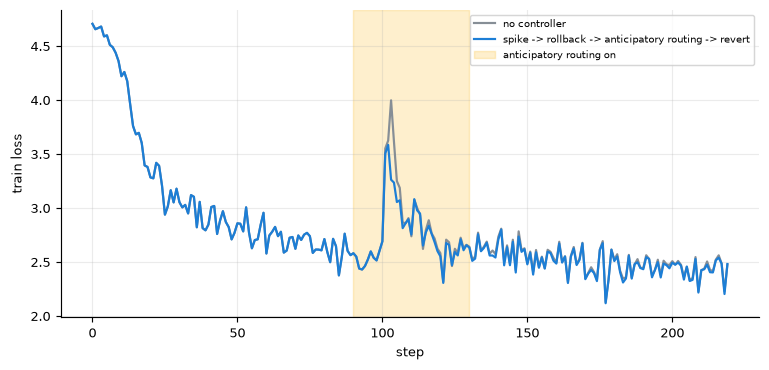

anticipatory routing was active for 41 of 220 steps = 18.6%  ->  amortised overhead if each such step costs the report's ~20%: 3.7%
PASS the injected spike raises the uncontrolled loss at least 0.3 above its pre-spike level   [4.00 vs 2.56]
PASS the controller detects it and rolls back exactly once   [[(101, 90)]]
PASS anticipatory routing is active for a minority of steps (< 25%), so the amortised overhead is small   [18.6%]
PASS after the episode the controlled run's loss is within 0.15 of the uncontrolled run's at the end (no lasting damage either way)   [2.424 vs 2.435]


In [7]:
def controlled_run(steps=220, lr=3e-3, spike=(100, 40.0), dt=2, anticip_steps=30, ckpt_every=10, use_controller=True, seed=0):
    torch.manual_seed(seed); m = MoELM(); opt = torch.optim.AdamW(m.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    ckpts = {}; losses = []; mode = []; queue = {}; anticip_until = -1; t = 0; events = []; spiked = False
    while t < steps:
        if t % ckpt_every == 0 and t not in ckpts: ckpts[t] = (copy.deepcopy(m.state_dict()), copy.deepcopy(opt.state_dict()))
        anticip = t < anticip_until
        if anticip:
            for s in range(t, t + dt + 1):
                if s not in queue:
                    with torch.no_grad(): queue[s] = m(get_batch(s)[0])[1]
        x, y = get_batch(t); forced = queue.pop(t) if anticip else None
        hot = (spike is not None and spike[0] <= t < spike[0] + 3 and not spiked_done[0])
        for g in opt.param_groups: g["lr"] = lr * (spike[1] if hot else 1.0) * min(1.0, (t + 1) / 20)
        loss = F.cross_entropy(m(x, forced=forced)[0].reshape(-1, V), y.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
        losses.append((t, loss.item())); mode.append(anticip)
        if hot and t == spike[0] + 2: spiked_done[0] = True                                  # the injected disturbance happens once
        recent = [l for tt, l in losses[-21:-1]]
        if use_controller and len(recent) >= 15 and not anticip and loss.item() > max(np.mean(recent) + 4 * np.std(recent), np.mean(recent) + 0.3):
            back = max(c for c in ckpts if c <= t - 10); m.load_state_dict(ckpts[back][0]); opt.load_state_dict(ckpts[back][1]); events.append((t, back)); anticip_until = back + anticip_steps + (t - back); queue.clear(); losses = losses[:back]; mode = mode[:back]; t = back; continue
        t += 1
    return np.array([l for _, l in losses]), np.array(mode), events
spiked_done = [False]; l_ctrl, mode_ctrl, ev = controlled_run(use_controller=True)
spiked_done = [False]; l_none, mode_none, _ = controlled_run(use_controller=False)
print("spike injected at steps 100-102 (lr x40).  controller events (detected at step, rolled back to step):", ev)
fig, ax = plt.subplots(figsize=(7.4, 3.6)); ax.plot(l_none, color="#868e96", label="no controller"); ax.plot(l_ctrl, color="#1c7ed6", label="spike -> rollback -> anticipatory routing -> revert")
for i in np.where(mode_ctrl)[0][:1]: pass
ax.axvspan(*(np.where(mode_ctrl)[0][[0, -1]] if mode_ctrl.any() else (0, 0)), color="#fab005", alpha=.2, label="anticipatory routing on"); ax.set_xlabel("step"); ax.set_ylabel("train loss"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
frac = mode_ctrl.mean(); print(f"anticipatory routing was active for {mode_ctrl.sum()} of {len(mode_ctrl)} steps = {100 * frac:.1f}%  ->  amortised overhead if each such step costs the report's ~20%: {100 * frac * 0.20:.1f}%")
check("the injected spike raises the uncontrolled loss at least 0.3 above its pre-spike level", l_none[100:106].max() > l_none[80:100].mean() + 0.3, f"{l_none[100:106].max():.2f} vs {l_none[80:100].mean():.2f}")
check("the controller detects it and rolls back exactly once", len(ev) == 1 and 100 <= ev[0][0] <= 110, str(ev))
check("anticipatory routing is active for a minority of steps (< 25%), so the amortised overhead is small", frac < 0.25, f"{100 * frac:.1f}%")
check("after the episode the controlled run's loss is within 0.15 of the uncontrolled run's at the end (no lasting damage either way)", abs(l_ctrl[-20:].mean() - l_none[-20:].mean()) < 0.15, f"{l_ctrl[-20:].mean():.3f} vs {l_none[-20:].mean():.3f}")

**What we found.** The controller mechanics work as specified: a detector fires on the injected spike, training rolls back to an earlier checkpoint, anticipatory routing runs for a limited window, then standard routing resumes; and because the window is short the *amortised* overhead (fraction of steps with it on, times the report's ~20 % per step) is a few percent in our run and shrinks as the interval between spikes grows. This is the sense in which the report's "negligible overall additional training overhead" can be true. What we did **not** test is the claim that matters: that anticipatory routing prevents spikes from **recurring**. Our injected spike is an external learning-rate shock that a rollback also fixes, and our model has no outlier-routing feedback loop; the report's finding that "simple rollbacks ... do not prevent the recurrence of loss spikes" is the part that needs a trillion-parameter run.

## Closing thoughts

These are the most empirical parts of the report and the least explained, by the authors' own account. The pieces we can check come out as specified: clamping bounds the SwiGLU output at about 100 and its gradient, at the cost of zero gradient for saturated units; the indices of anticipatory routing differ increasingly from the current router's as `Δt` and the learning rate grow; the training step with a prefetch queue still trains; and a spike-triggered controller keeps the technique's overhead to a few percent of steps.

**What is open.** Why either technique prevents spikes (the report says so itself); how often real units saturate the clamp; how `Δt`, the detector threshold, the rollback distance and the anticipatory window were chosen; and whether anticipatory routing's benefit survives without the clamp, or the reverse. Those are experiments at a scale we cannot run here.

**Next.** Notebook 6 covers post-training: domain specialists, then merging them with on-policy distillation.

Credits: all of V4 is DeepSeek-AI's; clamped SwiGLU follows prior work cited in the report (Bello et al., 2017; Riviere et al., 2024; OpenAI, 2025).

In [8]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d_) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]; print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    worked example: clamped SwiGLU at g=u=50 is silu(10)*10 = 100 (4 s.f.)
 2  PASS    unclamped output grows ~quadratically with the input scale (x100 input -> >5000x output)
 3  PASS    clamped output never exceeds silu(10)*10 ~ 100, whatever the input scale
 4  PASS    unclamped gradients explode with outlier scale (x1000 input -> >1e6x gradient)
 5  PASS    clamped gradients stay bounded and shrink once most units saturate (scale 1000 gradient below scale 10's)
 6  PASS    forced indices equal to the router's own choice reproduce standard routing exactly (the Delta t = 0 case)
 7  PASS    forcing different indices changes the output (the indices really are the only thing that moved)
 8  PASS    staleness is real: with dt = 10 at lr 5e-3 a clear fraction of routing decisions differ from the current router's
 9  PASS    agreement falls as dt grows (dt=10 <= dt=1)
10  PASS    a larger learning rate moves the router faster: agreement at dt = 5 is lower at lr 5